In [1]:
"""
YES24 베스트셀러 목록을 Selenium으로 수집해서
베스트셀러를 가장 많이 낸 출판사를 집계하는 스크립트

필요 패키지:
    pip install selenium pandas
(Selenium 4.6 이상은 크롬 드라이버를 자동으로 내려받으므로 webdriver-manager가 필요 없습니다.)
"""

import time
from collections import Counter

import pandas as pd
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait
from selenium.common.exceptions import TimeoutException, NoSuchElementException

# ── 설정 ────────────────────────────────────────────────
BASE_URL = "https://www.yes24.com/Product/Category/BestSeller"
CATEGORY = "001"     # 001 = 국내도서 전체
PAGE_SIZE = 24       # 한 페이지에 표시할 상품 수 (24, 40, 80 등)
MAX_PAGES = 10       # 몇 페이지까지 수집할지 (24 x 10 = 상위 240권)
DELAY = 1.5          # 페이지 사이 대기 시간(초) — 서버 부담을 줄이기 위해 유지 권장
TOP_N = 20           # 상위 몇 개 출판사를 출력할지


def create_driver(headless: bool = True) -> webdriver.Chrome:
    options = Options()
    if headless:
        options.add_argument("--headless=new")
    options.add_argument("--no-sandbox")
    options.add_argument("--disable-dev-shm-usage")
    options.add_argument("--window-size=1920,1080")
    options.add_argument(
        "user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    )
    return webdriver.Chrome(options=options)


def safe_text(parent, selector: str) -> str:
    """요소가 없으면 빈 문자열을 돌려준다."""
    try:
        return parent.find_element(By.CSS_SELECTOR, selector).text.strip()
    except NoSuchElementException:
        return ""


def scrape_page(driver, page: int) -> list[dict]:
    url = (f"{BASE_URL}?categoryNumber={CATEGORY}"
           f"&pageNumber={page}&pageSize={PAGE_SIZE}")
    driver.get(url)

    try:
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CSS_SELECTOR, "#yesBestList > li"))
        )
    except TimeoutException:
        print(f"[경고] {page}페이지 로딩 실패 또는 목록 없음")
        return []

    items = driver.find_elements(By.CSS_SELECTOR, "#yesBestList > li")
    books = []
    for idx, item in enumerate(items, start=1):
        title = safe_text(item, ".gd_name")
        if not title:            # 광고 등 상품이 아닌 li는 건너뜀
            continue
        books.append({
            "rank": (page - 1) * PAGE_SIZE + idx,
            "title": title,
            "author": safe_text(item, ".info_auth"),
            "publisher": safe_text(item, ".info_pub"),
            "date": safe_text(item, ".info_date"),
        })
    return books


def main():
    driver = create_driver(headless=True)
    all_books = []
    try:
        for page in range(1, MAX_PAGES + 1):
            books = scrape_page(driver, page)
            if not books:
                break
            all_books.extend(books)
            print(f"{page}페이지: {len(books)}권 수집 (누적 {len(all_books)}권)")
            time.sleep(DELAY)
    finally:
        driver.quit()

    if not all_books:
        print("수집된 데이터가 없습니다. CSS 선택자가 바뀌었는지 확인하세요.")
        return

    # ── 원본 데이터 저장 ─────────────────────────────
    df = pd.DataFrame(all_books)
    df.to_csv("yes24_bestsellers.csv", index=False, encoding="utf-8-sig")

    # ── 출판사별 집계 ───────────────────────────────
    counter = Counter(p for p in df["publisher"] if p)
    pub_df = (pd.DataFrame(counter.most_common(), columns=["publisher", "count"]))

    # 순위 가중 점수: 1위 책일수록 높은 점수 (단순 권수 외 보조 지표)
    total = len(df)
    df["score"] = total - df["rank"] + 1
    score = df.groupby("publisher")["score"].sum()
    best_rank = df.groupby("publisher")["rank"].min()
    pub_df["weighted_score"] = pub_df["publisher"].map(score)
    pub_df["best_rank"] = pub_df["publisher"].map(best_rank)

    pub_df.to_csv("yes24_publisher_ranking.csv", index=False, encoding="utf-8-sig")

    print(f"\n=== 베스트셀러 상위 {total}권 중 출판사 TOP {TOP_N} ===")
    print(pub_df.head(TOP_N).to_string(index=False))


if __name__ == "__main__":
    main()


1페이지: 24권 수집 (누적 24권)
2페이지: 24권 수집 (누적 48권)
3페이지: 24권 수집 (누적 72권)
4페이지: 24권 수집 (누적 96권)
5페이지: 24권 수집 (누적 120권)
6페이지: 24권 수집 (누적 144권)
7페이지: 24권 수집 (누적 168권)
8페이지: 24권 수집 (누적 192권)
9페이지: 24권 수집 (누적 216권)
10페이지: 24권 수집 (누적 240권)

=== 베스트셀러 상위 240권 중 출판사 TOP 20 ===
   publisher  count  weighted_score  best_rank
         민음사     15            2139          4
        문학동네     10            1331          1
      미우(대원)      7             728         84
공단기(에스티유니타스)      6             618         21
       상상스퀘어      6            1019         24
         김영사      5             476         85
       인플루엔셜      5             565         97
        현대지성      5             368        140
      페이지2북스      4             744         15
          대원      4             778         23
         크래커      4             750         30
     웅진지식하우스      4             533         35
          창비      4             460         91
         비룡소      4             385        108
    해커스어학연구소      4             

[완료] 소설/시/희곡 1페이지 - 24권
[완료] 소설/시/희곡 2페이지 - 24권
[완료] 에세이 1페이지 - 24권
[완료] 에세이 2페이지 - 24권
[완료] 경제경영 1페이지 - 24권
[완료] 경제경영 2페이지 - 24권
[완료] 자기계발 1페이지 - 24권
[완료] 자기계발 2페이지 - 24권
[완료] 인문 1페이지 - 24권
[완료] 인문 2페이지 - 24권
[완료] IT 모바일 1페이지 - 24권
[완료] IT 모바일 2페이지 - 24권

총 288권 수집 → yes24_bestseller.csv 저장

===== ① 분야별 가격 통계 =====
         도서수      평균가      중앙값    최저가    최고가
분야                                          
IT 모바일    48  23475.0  23400.0  16200  34200
경제경영      48  20172.0  19800.0   5000  44100
인문        48  18673.0  17235.0  10800  29700
자기계발      48  17807.0  17820.0   6480  26820
에세이       48  17475.0  16200.0  10800  55000
소설/시/희곡   48  15182.0  15120.0   7200  59400

===== ② 분야별 TOP 3 =====
     분야  순위                                도서명                                                                                                    저자   판매가
 IT 모바일   1                    클로드 코드 제대로 시작하기                                                                                              주홍

C:\Users\chaee\AppData\Local\Temp\ipykernel_44084\1084806242.py:189: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=price_stats.index, y=price_stats["평균가"], ax=axes[0], palette="Blues_d")
C:\Users\chaee\AppData\Local\Temp\ipykernel_44084\1084806242.py:195: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="분야", y="판매가", ax=axes[1], palette="Set2")


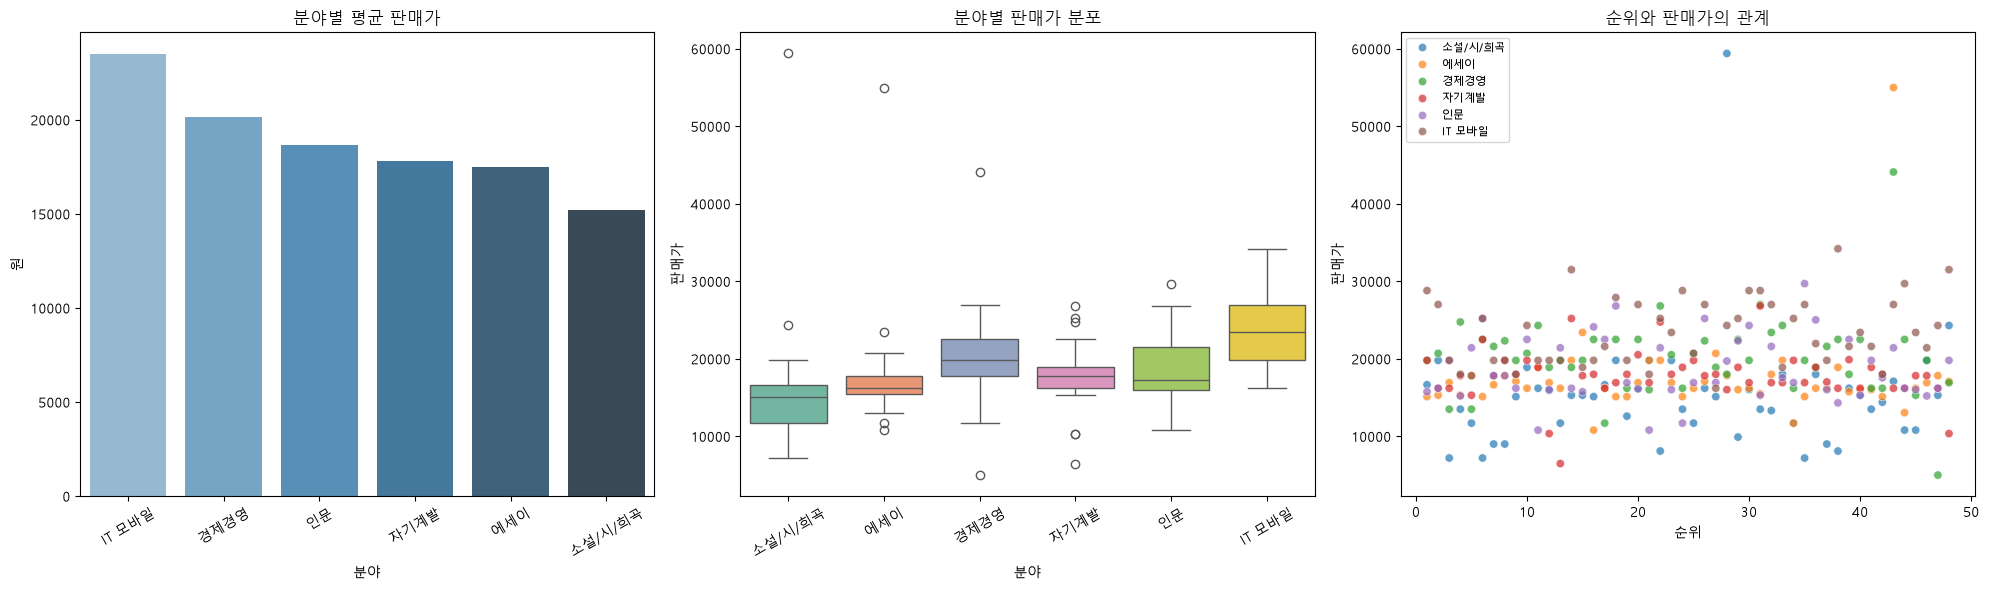

In [2]:
"""
YES24 분야별 베스트셀러 스크래핑 & 분석
- 수집 항목: 분야, 순위, 도서명, 저자, 출판사, 판매가
- 분석: 분야별 가격 통계, 다작(多作) 저자, 순위-가격 상관관계, 시각화

필요 패키지:
    pip install requests beautifulsoup4 pandas matplotlib seaborn
"""

import re
import time
import random

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

# ──────────────────────────────────────────────
# 1. 설정
# ──────────────────────────────────────────────
BASE_URL = "https://www.yes24.com/Product/Category/BestSeller"

# 분야별 카테고리 번호 (YES24 사이트에서 분야 클릭 후 URL의 categoryNumber 값으로 확인/수정하세요)
CATEGORIES = {
    "소설/시/희곡": "001001046",
    "에세이": "001001047",
    "경제경영": "001001025",
    "자기계발": "001001026",
    "인문": "001001019",
    "IT 모바일": "001001003",
}

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0 Safari/537.36"
    ),
    "Referer": "https://www.yes24.com/main/default.aspx",
}

PAGE_SIZE = 24      # 한 페이지당 도서 수
MAX_PAGES = 2       # 분야별로 가져올 페이지 수 (2 → 상위 48위)


# ──────────────────────────────────────────────
# 2. 유틸 함수
# ──────────────────────────────────────────────
def to_int(text: str):
    """'16,200원' → 16200"""
    digits = re.sub(r"[^\d]", "", text or "")
    return int(digits) if digits else None


def safe_text(tag):
    return tag.get_text(strip=True) if tag else ""


# ──────────────────────────────────────────────
# 3. 한 페이지 파싱
# ──────────────────────────────────────────────
def parse_page(html: str, category: str, start_rank: int):
    soup = BeautifulSoup(html, "html.parser")
    items = soup.select("#yesBestList > li")
    books = []

    for idx, li in enumerate(items):
        title = safe_text(li.select_one("a.gd_name"))
        if not title:
            continue

        # 순위: 페이지에 표시된 값이 있으면 사용, 없으면 위치로 계산
        rank_tag = li.select_one("em.ico.rank")
        rank = to_int(safe_text(rank_tag)) or (start_rank + idx)

        # 저자: 여러 명일 수 있으므로 a 태그를 모두 모음
        authors = [a.get_text(strip=True) for a in li.select(".info_auth a")]
        author = ", ".join(authors) if authors else safe_text(li.select_one(".info_auth"))

        publisher = safe_text(li.select_one(".info_pub a"))

        price = to_int(safe_text(li.select_one(".info_price .txt_num .yes_b")))
        if price is None:  # 구조가 다를 경우 대비
            price = to_int(safe_text(li.select_one(".yes_b")))

        books.append({
            "분야": category,
            "순위": rank,
            "도서명": title,
            "저자": author,
            "출판사": publisher,
            "판매가": price,
        })
    return books


# ──────────────────────────────────────────────
# 4. 분야별 수집
# ──────────────────────────────────────────────
def scrape_bestsellers():
    session = requests.Session()
    session.headers.update(HEADERS)
    all_books = []

    for category, code in CATEGORIES.items():
        for page in range(1, MAX_PAGES + 1):
            params = {
                "categoryNumber": code,
                "pageNumber": page,
                "pageSize": PAGE_SIZE,
            }
            try:
                res = session.get(BASE_URL, params=params, timeout=10)
                res.raise_for_status()
            except requests.RequestException as e:
                print(f"[실패] {category} {page}페이지: {e}")
                continue

            start_rank = (page - 1) * PAGE_SIZE + 1
            books = parse_page(res.text, category, start_rank)
            all_books.extend(books)
            print(f"[완료] {category} {page}페이지 - {len(books)}권")

            # 서버 부담을 줄이기 위해 요청 간 대기
            time.sleep(random.uniform(1.0, 2.0))

    return pd.DataFrame(all_books)


# ──────────────────────────────────────────────
# 5. 분석
# ──────────────────────────────────────────────
def analyze(df: pd.DataFrame):
    df = df.dropna(subset=["판매가"]).copy()
    df["판매가"] = df["판매가"].astype(int)

    print("\n===== ① 분야별 가격 통계 =====")
    price_stats = (
        df.groupby("분야")["판매가"]
        .agg(도서수="count", 평균가="mean", 중앙값="median", 최저가="min", 최고가="max")
        .round(0)
        .sort_values("평균가", ascending=False)
    )
    print(price_stats)

    print("\n===== ② 분야별 TOP 3 =====")
    top3 = df[df["순위"] <= 3].sort_values(["분야", "순위"])
    print(top3[["분야", "순위", "도서명", "저자", "판매가"]].to_string(index=False))

    print("\n===== ③ 베스트셀러에 여러 권 올린 저자 =====")
    author_cnt = (
        df.assign(저자=df["저자"].str.split(", "))
        .explode("저자")
        .query("저자 != ''")
        .groupby("저자")
        .agg(권수=("도서명", "count"), 평균순위=("순위", "mean"))
        .query("권수 >= 2")
        .sort_values(["권수", "평균순위"], ascending=[False, True])
        .round(1)
    )
    print(author_cnt.head(10) if not author_cnt.empty else "2권 이상인 저자 없음")

    print("\n===== ④ 분야별 순위-가격 상관계수 (Spearman) =====")
    print("(음수: 상위권일수록 비쌈 / 양수: 상위권일수록 저렴)")
    corr = df.groupby("분야").apply(
        lambda g: g["순위"].corr(g["판매가"], method="spearman")
    ).round(3)
    print(corr)

    print("\n===== ⑤ 출판사별 베스트셀러 수 TOP 10 =====")
    print(df["출판사"].value_counts().head(10))

    return df, price_stats


# ──────────────────────────────────────────────
# 6. 시각화
# ──────────────────────────────────────────────
def visualize(df: pd.DataFrame, price_stats: pd.DataFrame):
    # 한글 폰트 (Windows: Malgun Gothic / Mac: AppleGothic / Linux: NanumGothic)
    plt.rcParams["font.family"] = "Malgun Gothic"
    plt.rcParams["axes.unicode_minus"] = False

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # (1) 분야별 평균 가격
    sns.barplot(x=price_stats.index, y=price_stats["평균가"], ax=axes[0], palette="Blues_d")
    axes[0].set_title("분야별 평균 판매가")
    axes[0].set_ylabel("원")
    axes[0].tick_params(axis="x", rotation=30)

    # (2) 분야별 가격 분포
    sns.boxplot(data=df, x="분야", y="판매가", ax=axes[1], palette="Set2")
    axes[1].set_title("분야별 판매가 분포")
    axes[1].tick_params(axis="x", rotation=30)

    # (3) 순위 vs 가격
    sns.scatterplot(data=df, x="순위", y="판매가", hue="분야", ax=axes[2], alpha=0.7)
    axes[2].set_title("순위와 판매가의 관계")
    axes[2].legend(fontsize=8)

    plt.tight_layout()
    plt.savefig("yes24_bestseller_analysis.png", dpi=150)
    plt.show()


# ──────────────────────────────────────────────
# 7. 실행
# ──────────────────────────────────────────────
if __name__ == "__main__":
    df = scrape_bestsellers()

    if df.empty:
        print("수집된 데이터가 없습니다. CSS 선택자나 카테고리 번호를 확인하세요.")
    else:
        df.to_csv("yes24_bestseller.csv", index=False, encoding="utf-8-sig")
        print(f"\n총 {len(df)}권 수집 → yes24_bestseller.csv 저장")

        df, price_stats = analyze(df)
        visualize(df, price_stats)